In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_scoreplt.subplot(1, 2, 1)
plt.imshow(X_test.iloc[0].values.reshape(28, 28), cmap="gray")
plt.title("Original")

plt.subplot(1, 2, 2)
plt.imshow(X_noisy[0].reshape(28, 28), cmap="gray")
plt.title("Noisy")

plt.show()

In [5]:
df = pd.read_csv("01_mnist_784.csv")

X = df.drop("class", axis=1)
y = df["class"]

print(df.head())
print(df.shape)

   pixel1  pixel2  pixel3  pixel4  pixel5  pixel6  pixel7  pixel8  pixel9  \
0       0       0       0       0       0       0       0       0       0   
1       0       0       0       0       0       0       0       0       0   
2       0       0       0       0       0       0       0       0       0   
3       0       0       0       0       0       0       0       0       0   
4       0       0       0       0       0       0       0       0       0   

   pixel10  ...  pixel776  pixel777  pixel778  pixel779  pixel780  pixel781  \
0        0  ...         0         0         0         0         0         0   
1        0  ...         0         0         0         0         0         0   
2        0  ...         0         0         0         0         0         0   
3        0  ...         0         0         0         0         0         0   
4        0  ...         0         0         0         0         0         0   

   pixel782  pixel783  pixel784  class  
0         0         0

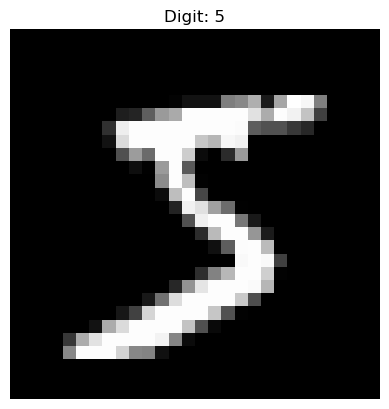

In [6]:
plt.imshow(X.iloc[0].values.reshape(28, 28), cmap="gray")
plt.title("Digit: " + str(y.iloc[0]))
plt.axis("off")
plt.show()

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

print("Model trained successfully")

Model trained successfully


In [8]:
pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, pred) * 100, "%")

Accuracy: 96.72857142857143 %


In [9]:
noise = np.random.normal(0, 25, X_test.shape)
X_noisy = np.clip(X_test + noise, 0, 255)

noisy_pred = model.predict(X_noisy)

print("Original Accuracy:", accuracy_score(y_test, pred) * 100)
print("Noisy Accuracy:", accuracy_score(y_test, noisy_pred) * 100

Original Accuracy: 96.72857142857143
Noisy Accuracy: 71.21428571428572


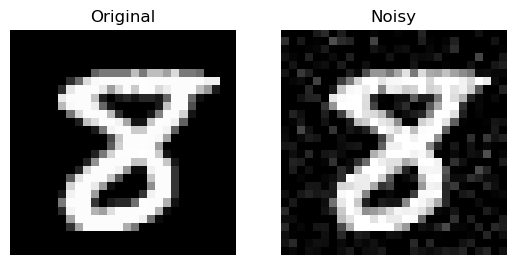

In [12]:
plt.subplot(1, 2, 1)
plt.imshow(X_test.iloc[0].values.reshape(28, 28), cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(X_noisy.iloc[0].values.reshape(28, 28), cmap="gray")
plt.title("Noisy")
plt.axis("off")

plt.show()